In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
master_df = pd.read_parquet(
    "../data/processed/master_df.parquet"
)

risk_df = pd.read_parquet(
    "../data/processed/risk_scoring.parquet"
)

forecast_df = pd.read_parquet(
    "../data/processed/weekly_sales.parquet"
)

In [5]:
total_revenue = master_df["total_value"].sum()

total_profit = master_df["profit"].sum()

total_customers = master_df["customer_id"].nunique()

total_products = master_df["sku_id"].nunique()

total_stores = master_df["store_id"].nunique()

print(f"Revenue: {total_revenue:,.2f}")

print(f"Profit: {total_profit:,.2f}")

print(f"Customers: {total_customers}")

print(f"Products: {total_products}")

print(f"Stores: {total_stores}")

Revenue: 10,902,909,080.73
Profit: 3,005,764,315.53
Customers: 10000
Products: 5000
Stores: 30


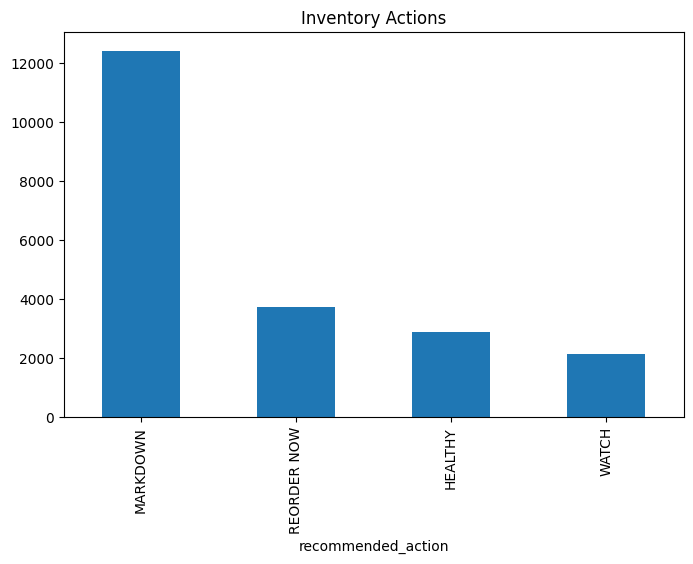

In [7]:
risk_df["recommended_action"].value_counts().plot(

    kind="bar",

    figsize=(8, 5)

)

plt.title("Inventory Actions")

plt.savefig(

    "../reports/images/dashboard_inventory_actions.png",

    bbox_inches="tight"

)

plt.show()

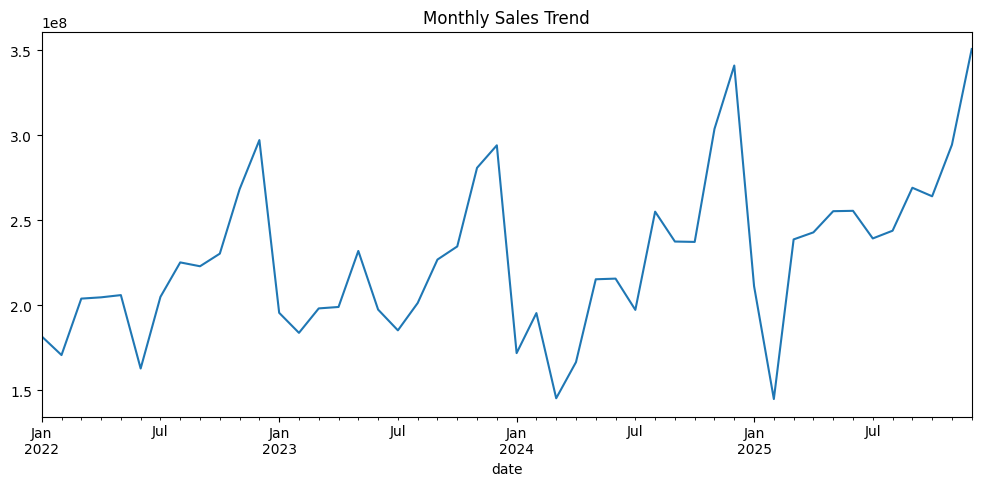

In [9]:
monthly_sales = (

    master_df

    .groupby(

        master_df["date"].dt.to_period("M")

    )["total_value"]

    .sum()

)

monthly_sales.plot(

    figsize=(12, 5)

)

plt.title("Monthly Sales Trend")

plt.savefig(

    "../reports/images/dashboard_monthly_sales.png",

    bbox_inches="tight"

)

plt.show()

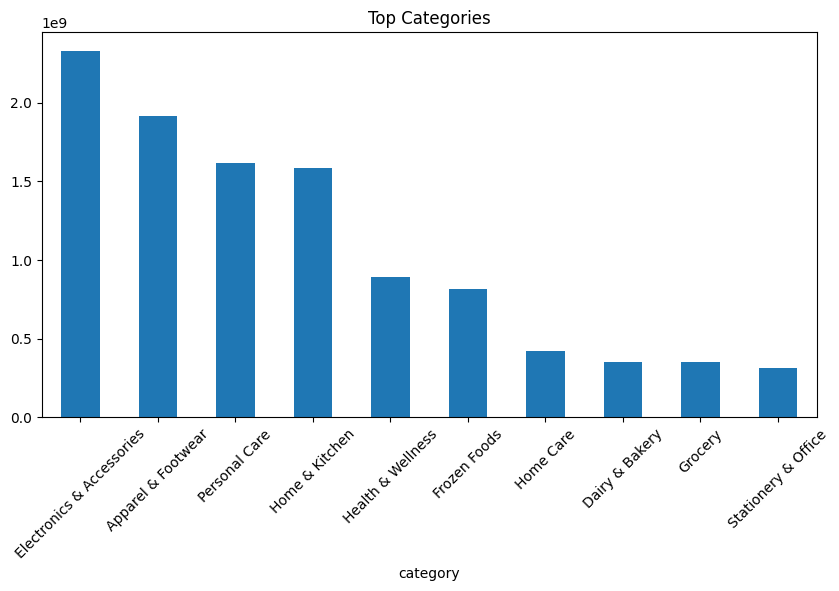

In [11]:
category_sales = (

    master_df

    .groupby("category")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(10)

)

category_sales.plot(

    kind="bar",

    figsize=(10, 5)

)

plt.title("Top Categories")

plt.xticks(rotation=45)

plt.savefig(

    "../reports/images/dashboard_categories.png",

    bbox_inches="tight"

)

plt.show()

In [20]:
risk_skus = risk_df[
    risk_df["recommended_action"] == "REORDER NOW"
]["sku_id"]

print("Number of rows:", len(risk_skus))

print("Unique SKUs:", risk_skus.nunique())

print(risk_skus.head())

Number of rows: 3746
Unique SKUs: 958
12    SKU00500
16    SKU01037
17    SKU01152
22    SKU02381
36    SKU03546
Name: sku_id, dtype: object


In [22]:
master_df[
    master_df["sku_id"].isin(risk_skus)
].shape

(4829713, 45)

In [26]:
revenue_at_risk = (

    master_df[
        master_df["sku_id"].isin(risk_skus)
    ]

    .groupby("sku_id")["total_value"]

    .sum()

    .sort_values(ascending=False)

    .head(20)

)

print(revenue_at_risk)

sku_id
SKU04321    1.066898e+09
SKU03727    2.614215e+08
SKU04329    9.468604e+07
SKU04596    8.894259e+07
SKU01371    8.408248e+07
SKU03053    8.407665e+07
SKU01189    7.029371e+07
SKU04551    6.920131e+07
SKU04157    6.910185e+07
SKU04571    6.249078e+07
SKU00994    5.385405e+07
SKU02692    5.205832e+07
SKU00728    5.075535e+07
SKU03323    5.012257e+07
SKU01363    5.009248e+07
SKU02833    4.651355e+07
SKU02141    4.457984e+07
SKU04154    4.269980e+07
SKU00531    3.905582e+07
SKU02368    3.209433e+07
Name: total_value, dtype: float64


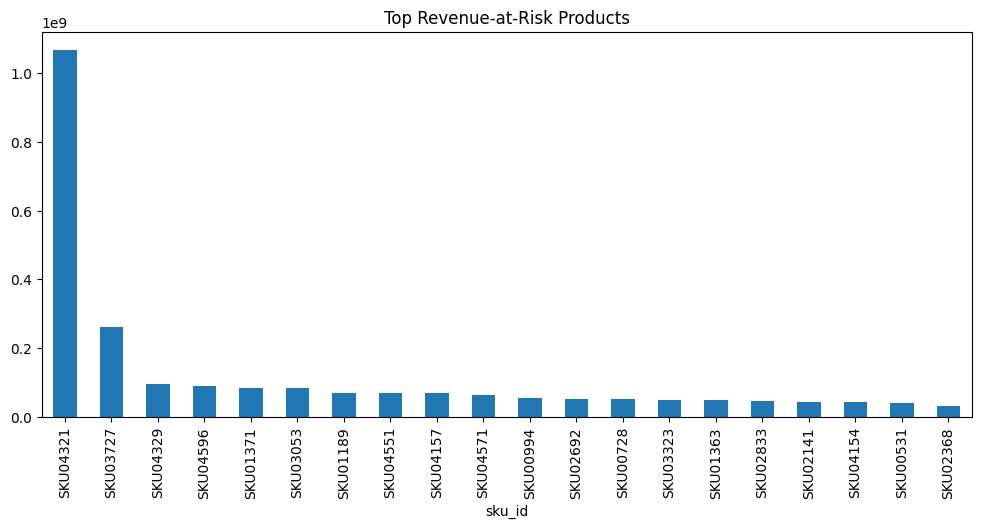

In [28]:
if len(revenue_at_risk) > 0:

    revenue_at_risk.plot(
        kind="bar",
        figsize=(12, 5)
    )

    plt.title("Top Revenue-at-Risk Products")

    plt.xticks(rotation=90)

    plt.show()

else:

    print("No data found")

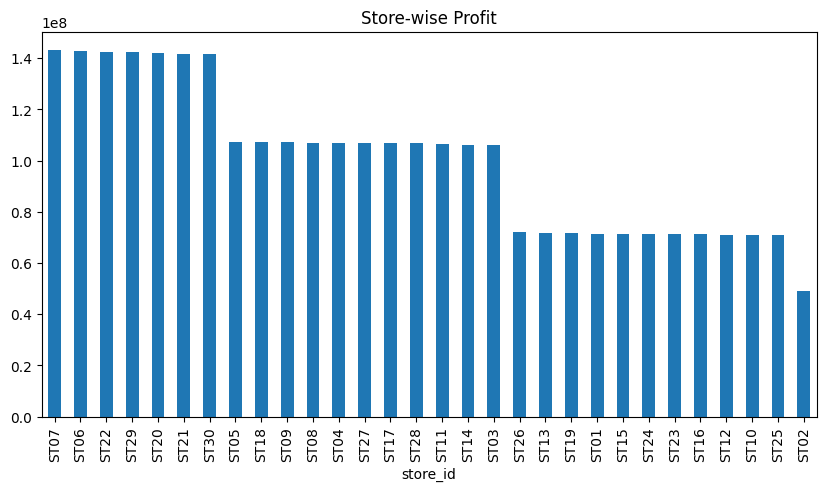

In [15]:
store_risk = (

    master_df

    .groupby("store_id")["profit"]

    .sum()

    .sort_values(ascending=False)

)

store_risk.plot(

    kind="bar",

    figsize=(10, 5)

)

plt.title("Store-wise Profit")

plt.savefig(

    "../reports/images/dashboard_store_profit.png",

    bbox_inches="tight"

)

plt.show()

# Executive Summary

- Total revenue generated: ₹10.9 billion
- Total profit generated: ₹3.0 billion
- 22.13% of revenue is exposed to inventory risk.
- SKU04321 alone contributes 9.79% of total revenue.
- 17.65% of products require immediate replenishment.
- 58.56% of products are overstocked and require markdown strategies.
- Seasonal-naive forecasting outperformed Random Forest forecasting.
- Inventory optimization can significantly reduce business losses.